# SITL flight scorecard

Point this notebook at any ArduPilot DataFlash log (`flight.BIN` / `logs/0000000N.BIN`) from a
drone SITL run. It splits the flight into phases and plots controller performance for each one.
Each metric gets a letter grade against editable threshold bounds, and the notebook ends with an
overall grade.

**Use.** Open it from launchpad (`spsage`) and set `LOG_PATH` in the next cell to the log you want to
score, then *Run All*, or re-run from that cell down. The cell also lists the SITL logs it finds
under `DATA_ROOT`, so you can copy a path from there. As saved, it scores the X-frame trajectory run
from anixpkgs #646.

**What adapts to the log.** Every section checks which messages are present. A stock-only flight
gets the stock-controller sections. A flight with the custom INDI controller (`INDI`, `INDB`, `INDC`
messages from `AC_CustomControl_INDI`) also gets the inner-loop, outer-loop, and measured-RPM
sections. A metric that can't be computed is shown as `n/a` and doesn't count toward the grade.

**Grading.** All metrics are *lower is better*. Each one has bounds `(A, B, C)`: a value ≤ A gets
an A, ≤ B a B, ≤ C a C, and anything above C an F. Metrics marked **gating** fail the flight on an F.
**Diagnostic** metrics count toward the average grade but can't fail the flight on their own. The
bounds are engineering defaults for this SITL setup, not ArduPilot standards. The exceptions are
the 1 rad/s handover gate, the 0.6 ω̇-NRMSE gate, the 2 % saturation gate, and the vibration
levels, which come from the harness gates or the ArduPilot wiki. Edit `THRESHOLDS` to retune.

In [1]:
from pathlib import Path

DATA_ROOT = Path("/data/andrew/dev/drone/data")
LOG_PATH = DATA_ROOT / "handover-trajectory-frame-x" / "flight.BIN"   # <- the log to score
CASE_NAMES = None          # names for custom outer-loop blocks; None = read indi_flatness_flown.json if present
AIRBORNE_ALT_M = 1.0       # CTUN altitude above home that counts as airborne
HOVER_SPEED_M_S = 0.1      # stock target speed below which the vehicle is "holding"
HOVER_SETTLE_S = 1.0       # trimmed from the start of each hold window
EDGE_TRIM_S = 1.5          # engagement / end transient excluded from steady tracking
MIN_EXCITATION_RAD_S2 = 1.0  # omega_dot NRMSE is only graded on axes excited above this RMS
ANIMATE = True
MAX_ANIMATION_FRAMES = 150

print("SITL logs under", DATA_ROOT)
for candidate in sorted(DATA_ROOT.glob("**/*.BIN")):
    marker = "  <- LOG_PATH" if candidate == Path(LOG_PATH) else ""
    print(f"  {candidate}  ({candidate.stat().st_size / 1e6:.1f} MB){marker}")

SITL logs under /data/andrew/dev/drone/data
  /data/andrew/dev/drone/data/guided-handover-linearized-attitude/logs/00000001.BIN  (18.6 MB)
  /data/andrew/dev/drone/data/guided-handover-linearized-position/logs/00000001.BIN  (18.7 MB)
  /data/andrew/dev/drone/data/guided-handover-linearized-position-indi/logs/00000001.BIN  (20.7 MB)
  /data/andrew/dev/drone/data/guided-handover-normal-position/logs/00000001.BIN  (18.5 MB)
  /data/andrew/dev/drone/data/handover-trajectory-frame-x/flight.BIN  (11.8 MB)  <- LOG_PATH
  /data/andrew/dev/drone/data/handover-trajectory-g1-measured/flight.BIN  (11.7 MB)
  /data/andrew/dev/drone/data/handover-trajectory-run/flight.BIN  (19.7 MB)
  /data/andrew/dev/drone/data/indi-measured-rpm-trajectory-vm/flight.BIN  (11.2 MB)
  /data/andrew/dev/drone/data/probe-corrected-01/logs/00000001.BIN  (24.3 MB)
  /data/andrew/dev/drone/data/probe-old-linear/logs/00000001.BIN  (24.3 MB)
  /data/andrew/dev/drone/data/probe-old-linear-02/logs/00000001.BIN  (4.7 MB)
  /dat

In [2]:
THRESHOLDS = {
    # key: (A, B, C) upper bounds, unit, gating, label, explanation
    "hover_rate_peak": ((0.1, 0.3, 1.0), "rad/s", True, "Stock hold: peak roll/pitch rate",
        "Peak |(p, q)| from the IMU while the stock controller holds position (custom controller off, "
        "target speed ≈ 0). A healthy hold is nearly motionless. C = the harness's 1 rad/s handover gate. "
        "A limit cycle (for example a mixer that doesn't match the plant) fails here first."),
    "hover_buzz": ((0.5, 2.0, 5.0), "deg/s", True, "Stock hold: rate buzz",
        "RMS of the high-passed roll/pitch gyro (0.5 s moving average removed) during stock hold. Measures "
        "oscillation that the low-rate attitude log hides."),
    "engaged_buzz": ((3.0, 8.0, 15.0), "deg/s", True, "Custom controller: rate buzz",
        "The same high-pass gyro RMS while the custom controller is engaged. Maneuvering adds some legitimate "
        "content, so the bounds are looser. An inner-loop limit cycle drives this sharply up."),
    "attitude_tracking": ((0.5, 1.5, 4.0), "deg", False, "Stock: attitude tracking RMS",
        "RMS of ATT desired − actual roll/pitch while the stock controller flies (custom controller off). "
        "ATT is logged at about 10 Hz."),
    "altitude_tracking": ((0.1, 0.3, 0.75), "m", False, "Stock: altitude tracking RMS",
        "RMS of CTUN desired − actual altitude while the stock controller flies."),
    "stock_position_tracking": ((0.1, 0.3, 1.0), "m", False, "Stock: horizontal position tracking RMS",
        "RMS horizontal distance between the stock position-controller target and the estimate "
        "(PSCN/PSCE) while the stock controller flies."),
    "outer_tracking_steady": ((0.1, 0.3, 0.75), "m", True, "Custom outer loop: steady tracking RMS (worst block)",
        "Per engaged outer-loop block (INDB.FB = 0), RMS of |reference − measured position| excluding "
        "the first and last EDGE_TRIM_S. Worst block shown."),
    "outer_engagement_peak": ((0.3, 1.0, 2.5), "m", False, "Custom outer loop: transient peak (worst block)",
        "Largest position error in the first/last EDGE_TRIM_S of any block. Usually reflects how the "
        "harness sequences references (origin latch, abrupt stop) rather than the controller."),
    "omega_nrmse": ((0.3, 0.45, 0.6), "", True, "INDI: ω̇ inversion NRMSE (worst excited roll/pitch)",
        "RMS(predicted − measured ω̇) / RMS(measured ω̇) on roll/pitch, only on axes excited above "
        "MIN_EXCITATION_RAD_S2. Measures whether the effectiveness model inverts the plant. "
        "C = the frozen 0.6 harness gate."),
    "omega_lag": ((10.0, 25.0, 50.0), "ms", False, "INDI: ω̇ prediction → measurement lag",
        "Time shift of the measurement that minimizes NRMSE (worst excited axis). A large lag means the "
        "prediction leads the plant: unmodeled actuator or filter delay."),
    "indi_saturation": ((0.001, 0.01, 0.02), "frac", True, "INDI: saturation fraction",
        "Fraction of INDI ticks with the saturation flag set while engaged. C = the 2 % harness gate."),
    "rpm_fallback": ((0.01, 0.1, 0.5), "frac", True, "INDI: measured-RPM fallback fraction",
        "Fraction of INDC ticks where RPM telemetry was stale and the measured-actuator path fell back."),
    "motor_saturation": ((0.001, 0.01, 0.05), "frac", True, "Motors: output at a limit",
        "Fraction of airborne RCOU samples where any motor is within 2 % of its PWM min or max."),
    "motor_hover_spread": ((2.0, 5.0, 10.0), "% range", False, "Motors: hover output spread",
        "Max − min of the per-motor mean PWM during stock hold, as a percent of the PWM range. A large "
        "spread means trim, CG, or layout asymmetry."),
    "ekf_test_ratio": ((0.3, 0.5, 1.0), "", True, "Estimator: peak innovation test ratio",
        "Max of the EKF3 core-0 velocity, position, and height innovation test ratios (XKF4 SV/SP/SH) while "
        "airborne. Values ≥ 1 mean measurements are being rejected."),
    "vibration": ((15.0, 30.0, 60.0), "m/s²", False, "Vibration: peak VIBE level",
        "Peak IMU-0 vibration level (VIBE). Bounds follow the ArduPilot guidance (< 30 fine, > 60 bad). "
        "Usually near zero in SITL."),
}

## Load the log

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from pymavlink import DFReader

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

MESSAGE_TYPES = ["IMU", "ATT", "RATE", "CTUN", "PSCN", "PSCE", "PSCD", "RCOU", "ESC", "SIM",
                 "XKF1", "XKF4", "VIBE", "INDB", "INDI", "INDC"]
# Multi-instance messages: keep only instance/core 0.
INSTANCE_FIELD = {"IMU": "I", "XKF1": "C", "XKF4": "C", "VIBE": "IMU"}


def load_dataflash(path):
    log = DFReader.DFReader_binary(str(path))
    rows = {k: [] for k in MESSAGE_TYPES}
    parameters, text, modes, arming = {}, [], [], []
    while (m := log.recv_match(type=MESSAGE_TYPES + ["PARM", "MSG", "MODE", "ARM"])) is not None:
        kind = m.get_type()
        if kind == "PARM":
            parameters[m.Name] = m.Value
        elif kind == "MSG":
            text.append((m.TimeUS / 1e6, m.Message))
        elif kind == "MODE":
            modes.append((m.TimeUS / 1e6, m.Mode))
        elif kind == "ARM":
            arming.append((m.TimeUS / 1e6, int(m.ArmState)))
        elif kind in INSTANCE_FIELD and getattr(m, INSTANCE_FIELD[kind]) != 0:
            continue
        else:
            rows[kind].append(m.to_dict())
    series = {}
    for kind, messages in rows.items():
        if messages:
            fields = [f for f in messages[0] if f != "mavpackettype"]
            series[kind] = {f: np.array([msg[f] for msg in messages]) for f in fields}
            series[kind]["t"] = series[kind]["TimeUS"] / 1e6
    return series, parameters, text, modes, arming


log_path = Path(LOG_PATH)
S, PARAMS, TEXT, MODES, ARMING = load_dataflash(log_path)
has = lambda *kinds: all(k in S for k in kinds)

# Optional sidecar files the measured-RPM trajectory harness writes next to flight.BIN.
sidecar_flown = log_path.parent / "indi_flatness_flown.json"
if CASE_NAMES is None and sidecar_flown.exists():
    CASE_NAMES = [c["case"] for c in json.loads(sidecar_flown.read_text())]

print(f"log: {log_path}  ({log_path.stat().st_size / 1e6:.1f} MB)")
print("messages:", {k: len(v["t"]) for k, v in S.items()})
print(f"FRAME_CLASS={PARAMS.get('FRAME_CLASS')}  FRAME_TYPE={PARAMS.get('FRAME_TYPE')}  "
      f"CC_TYPE={PARAMS.get('CC_TYPE')}  CC3_USE_RPM={PARAMS.get('CC3_USE_RPM')}")
for t, message in TEXT:
    if any(s in message.lower() for s in ("frame:", "custom controller", "failsafe", "crash",
                                            "error", "variance", "arming", "disarming")):
        print(f"  {t:8.2f} s  {message}")

log: /data/andrew/dev/drone/data/handover-trajectory-frame-x/flight.BIN  (11.8 MB)
messages: {'IMU': 2428, 'ATT': 971, 'RATE': 971, 'CTUN': 971, 'PSCN': 819, 'PSCE': 819, 'PSCD': 819, 'RCOU': 971, 'ESC': 38840, 'SIM': 971, 'XKF1': 971, 'XKF4': 971, 'VIBE': 971, 'INDB': 21406, 'INDI': 21407, 'INDC': 21406}
FRAME_CLASS=1.0  FRAME_TYPE=1.0  CC_TYPE=3.0  CC3_USE_RPM=1.0
     27.78 s  Frame: QUAD/X
     29.98 s  Arming motors
     31.98 s  Disarming motors
     47.64 s  Arming motors
     57.63 s  Disarming motors
     57.69 s  Arming motors
     71.23 s  Custom controller is OFF
     72.03 s  Custom controller is ON


## Flight phases

The scores are computed per phase, so the phases are derived first.

* **airborne**: armed and CTUN altitude above `AIRBORNE_ALT_M`.
* **custom engaged**: between `Custom controller is ON` and the next `OFF` (or the INDI log span if
  those messages are missing).
* **outer active**: contiguous `INDB.FB == 0` blocks of at least 1 s, where the DDS flatness reference
  drives the custom outer loop. Each block is one trajectory case.
* **stock flight**: airborne with the custom controller off.
* **stock hold**: stock flight with target speed below `HOVER_SPEED_M_S`, with the first
  `HOVER_SETTLE_S` of each window trimmed.

In [4]:
def intervals_from_mask(t, mask, min_duration=0.0, gap=None):
    # Contiguous True runs of mask -> [(t_start, t_end)]. gap splits runs at sampling gaps.
    mask = np.asarray(mask, bool)
    breaks = np.zeros_like(mask)
    if gap is not None and len(t) > 1:
        breaks[1:] = np.diff(t) > gap
    out, start = [], None
    for k, on in enumerate(mask):
        if start is not None and (not on or breaks[k]):
            out.append((t[start], t[k - 1]))
            start = None
        if on and start is None:
            start = k
    if start is not None:
        out.append((t[start], t[-1]))
    return [(a, b) for a, b in out if b - a >= min_duration]


def within(t, intervals):
    t = np.asarray(t)
    mask = np.zeros(t.shape, bool)
    for a, b in intervals:
        mask |= (t >= a) & (t <= b)
    return mask


def intersect(a_list, b_list):
    out = []
    for a0, a1 in a_list:
        for b0, b1 in b_list:
            lo, hi = max(a0, b0), min(a1, b1)
            if hi > lo:
                out.append((lo, hi))
    return out


def subtract(a_list, b_list):
    out = list(a_list)
    for b0, b1 in b_list:
        nxt = []
        for a0, a1 in out:
            if b1 <= a0 or b0 >= a1:
                nxt.append((a0, a1))
                continue
            if b0 > a0:
                nxt.append((a0, b0))
            if b1 < a1:
                nxt.append((b1, a1))
        out = nxt
    return out


t_end = max(v["t"][-1] for v in S.values())
armed, arm_start = [], None
for t, state in ARMING:
    if state and arm_start is None:
        arm_start = t
    elif not state and arm_start is not None:
        armed.append((arm_start, t))
        arm_start = None
if arm_start is not None:
    armed.append((arm_start, t_end))

if has("CTUN"):
    airborne = intersect(intervals_from_mask(S["CTUN"]["t"], S["CTUN"]["Alt"] > AIRBORNE_ALT_M, 0.5), armed)
elif has("SIM"):
    rel = S["SIM"]["Alt"] - S["SIM"]["Alt"][0]
    airborne = intersect(intervals_from_mask(S["SIM"]["t"], rel > AIRBORNE_ALT_M, 0.5), armed)
else:
    airborne = armed

engaged, on_time = [], None
for t, message in TEXT:
    if message == "Custom controller is ON" and on_time is None:
        on_time = t
    elif message == "Custom controller is OFF" and on_time is not None:
        engaged.append((on_time, t))
        on_time = None
if on_time is not None:
    engaged.append((on_time, armed[-1][1] if armed else t_end))
if not engaged and has("INDI"):
    engaged = intervals_from_mask(S["INDI"]["t"], np.ones(len(S["INDI"]["t"]), bool), 0.5, gap=0.2)

outer_blocks = []
if has("INDB"):
    outer_blocks = intervals_from_mask(S["INDB"]["t"], S["INDB"]["FB"] == 0, 1.0, gap=0.2)
block_names = [(CASE_NAMES[k] if CASE_NAMES and k < len(CASE_NAMES) else f"block {k + 1}")
               for k in range(len(outer_blocks))]

stock_flight = subtract(airborne, engaged)
stock_hold = []
if has("PSCN", "PSCE", "PSCD"):
    tp = S["PSCN"]["t"]
    speed = np.sqrt(S["PSCN"]["TVN"] ** 2 + np.interp(tp, S["PSCE"]["t"], S["PSCE"]["TVE"]) ** 2
                    + np.interp(tp, S["PSCD"]["t"], S["PSCD"]["TVD"]) ** 2)
    holding = intervals_from_mask(tp, speed < HOVER_SPEED_M_S, HOVER_SETTLE_S + 0.5, gap=0.5)
    stock_hold = [(a + HOVER_SETTLE_S, b) for a, b in intersect(holding, stock_flight)
                  if b - a > HOVER_SETTLE_S + 0.5]
else:
    stock_hold = [(a + 3.0, b) for a, b in stock_flight if b - a > 4.0]

span = lambda ivs: sum(b - a for a, b in ivs)
for name, ivs in [("armed", armed), ("airborne", airborne), ("custom engaged", engaged),
                  ("outer active", outer_blocks), ("stock flight", stock_flight), ("stock hold", stock_hold)]:
    print(f"{name:15s} {span(ivs):7.1f} s  {[(round(float(a), 1), round(float(b), 1)) for a, b in ivs][:6]}")
if not armed:
    print("NOTE: the vehicle never armed; check the MSG log above for prearm failures. Nothing to grade.")
elif not airborne:
    print(f"NOTE: armed but never above {AIRBORNE_ALT_M} m; flight metrics will be n/a.")

armed              79.8 s  [(30.0, 32.0), (47.6, 57.6), (57.7, 125.5)]
airborne           63.2 s  [(62.3, 125.5)]
custom engaged     53.5 s  [(72.0, 125.5)]
outer active       39.2 s  [(78.9, 101.3), (104.1, 121.0)]
stock flight        9.7 s  [(62.3, 72.0)]
stock hold          3.7 s  [(68.3, 72.0)]


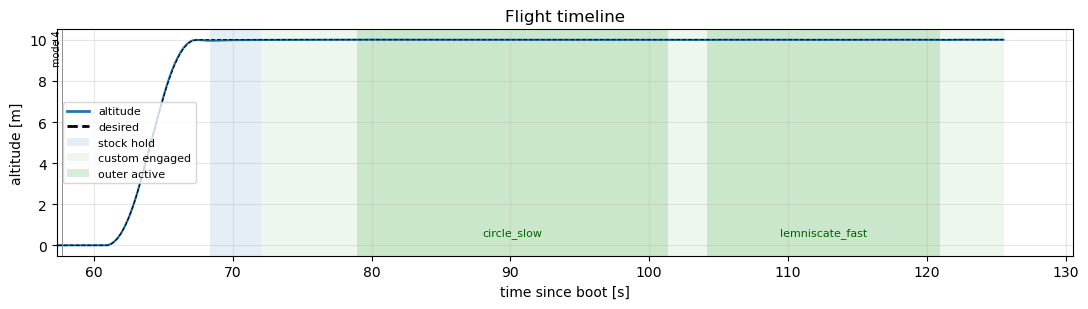

In [5]:
PHASE_STYLE = {"stock hold": ("tab:blue", 0.12), "custom engaged": ("tab:green", 0.08),
               "outer active": ("tab:green", 0.18)}


def shade(ax, legend=False):
    for label, ivs in [("stock hold", stock_hold), ("custom engaged", engaged), ("outer active", outer_blocks)]:
        color, alpha = PHASE_STYLE[label]
        for k, (a, b) in enumerate(ivs):
            ax.axvspan(a, b, color=color, alpha=alpha, lw=0, label=label if legend and k == 0 else None)


def legend(ax, **kwargs):
    handle = ax.legend(**kwargs)
    for line in handle.get_lines():
        line.set_linewidth(2.0)
    return handle


def flight_xlim(ax):
    if airborne:
        ax.set_xlim(airborne[0][0] - 5, airborne[-1][1] + 5)


fig, ax = plt.subplots(figsize=(11, 3.2))
if has("CTUN"):
    ax.plot(S["CTUN"]["t"], S["CTUN"]["Alt"], label="altitude")
    ax.plot(S["CTUN"]["t"], S["CTUN"]["DAlt"], "k--", lw=0.8, label="desired")
shade(ax, legend=True)
for t, mode in MODES:
    if airborne and not (airborne[0][0] - 5 <= t <= airborne[-1][1] + 5):
        continue
    ax.axvline(t, color="gray", lw=0.6)
    ax.annotate(f"mode {mode}", (t, ax.get_ylim()[1]), fontsize=7, rotation=90, va="top", ha="right")
for k, (a, b) in enumerate(outer_blocks):
    ax.annotate(block_names[k], ((a + b) / 2, 0.5), ha="center", fontsize=8, color="darkgreen")
ax.set_ylabel("altitude [m]")
ax.set_xlabel("time since boot [s]")
ax.set_title("Flight timeline")
legend(ax, fontsize=8, loc="center left")
flight_xlim(ax)
fig.tight_layout()

## Scoring helpers

`record()` grades one metric and stores it for the final scorecard.

In [6]:
GRADE_POINTS = {"A": 4, "B": 3, "C": 2, "F": 0}
GRADE_COLORS = {"A": "#2e7d32", "B": "#7cb342", "C": "#f9a825", "F": "#c62828", "n/a": "#9e9e9e"}
SCORES = {}


def letter(value, bounds):
    if value is None or not np.isfinite(value):
        return "n/a"
    for grade, bound in zip("ABC", bounds):
        if value <= bound:
            return grade
    return "F"


def record(key, value, detail=""):
    bounds, unit, gating, label, _ = THRESHOLDS[key]
    value = float(value) if value is not None else float("nan")
    SCORES[key] = {"value": value, "grade": letter(value, bounds), "detail": detail}
    print(f"[{SCORES[key]['grade']:>3s}] {label}: {value:.4g} {unit}  (A≤{bounds[0]:g} B≤{bounds[1]:g} "
          f"C≤{bounds[2]:g}){'  ' + detail if detail else ''}")


def rms(x):
    x = np.asarray(x, float)
    return float(np.sqrt(np.mean(x ** 2))) if x.size else float("nan")


def plot_phase(ax, t, y, intervals, **kwargs):
    # Full trace in light gray for context; samples inside intervals in color.
    ax.plot(t, y, color="0.8", lw=0.6)
    ax.plot(t, np.where(within(t, intervals), y, np.nan), **kwargs)


def high_pass(t, x, window_s=0.5):
    dt = np.median(np.diff(t))
    n = max(3, int(round(window_s / dt)) | 1)
    kernel = np.ones(n) / n
    return x - np.convolve(np.pad(x, n // 2, mode="edge"), kernel, mode="valid")

## 1. Body-rate stability and buzz

Roll/pitch body rates come from the IMU, which is logged faster than `RATE` or `ATT`. The 10 Hz `RATE`
log aliases rate-loop oscillation into a misleading near-constant value, so it isn't used to score
buzz. The lower panel high-passes the gyro by removing a 0.5 s moving average. What remains is
oscillation rather than maneuvering.

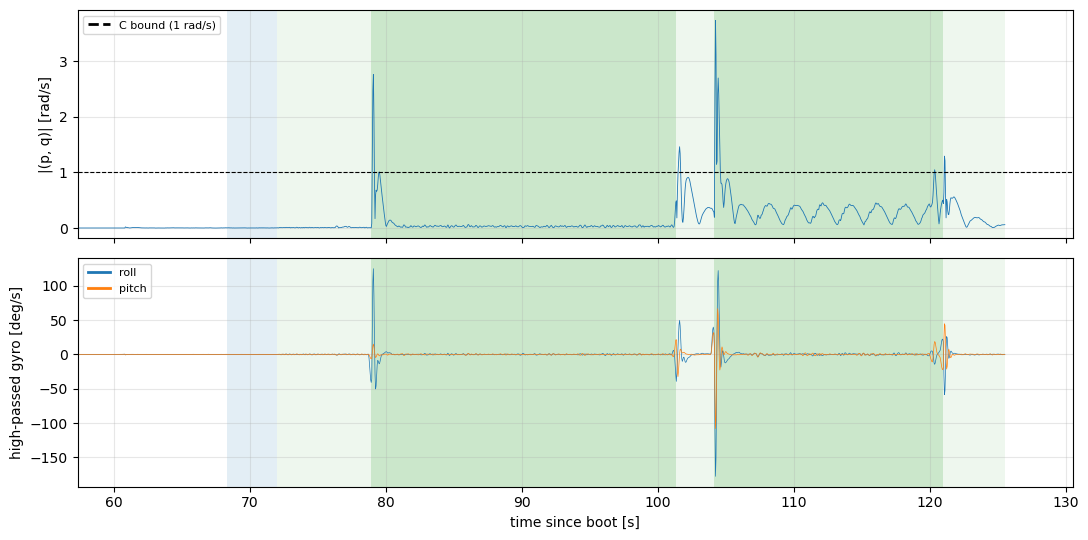

[  A] Stock hold: peak roll/pitch rate: 0.005373 rad/s  (A≤0.1 B≤0.3 C≤1)  over 3.7 s of stock hold
[  A] Stock hold: rate buzz: 0.06579 deg/s  (A≤0.5 B≤2 C≤5)
[  C] Custom controller: rate buzz: 11.89 deg/s  (A≤3 B≤8 C≤15)  over 53.5 s engaged


In [7]:
if has("IMU"):
    imu = S["IMU"]
    t_imu = imu["t"]
    rate = np.hypot(imu["GyrX"], imu["GyrY"])
    hp = np.degrees(np.column_stack([high_pass(t_imu, imu["GyrX"]), high_pass(t_imu, imu["GyrY"])]))

    fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    axes[0].plot(t_imu, rate, lw=0.6)
    axes[0].axhline(THRESHOLDS["hover_rate_peak"][0][2], color="k", ls="--", lw=0.8, label="C bound (1 rad/s)")
    axes[0].set_ylabel("|(p, q)| [rad/s]")
    legend(axes[0], fontsize=8)
    axes[1].plot(t_imu, hp[:, 0], lw=0.5, label="roll")
    axes[1].plot(t_imu, hp[:, 1], lw=0.5, label="pitch")
    axes[1].set_ylabel("high-passed gyro [deg/s]")
    axes[1].set_xlabel("time since boot [s]")
    legend(axes[1], fontsize=8)
    for ax in axes:
        shade(ax)
        flight_xlim(ax)
    fig.tight_layout()
    plt.show()

    hold = within(t_imu, stock_hold)
    if hold.any():
        record("hover_rate_peak", rate[hold].max(), f"over {span(stock_hold):.1f} s of stock hold")
        record("hover_buzz", max(rms(hp[hold, 0]), rms(hp[hold, 1])))
    else:
        record("hover_rate_peak", None, "no stock hold window")
        record("hover_buzz", None)
    on = within(t_imu, engaged)
    record("engaged_buzz", max(rms(hp[on, 0]), rms(hp[on, 1])) if on.any() else None,
           f"over {span(engaged):.1f} s engaged" if on.any() else "custom controller never engaged")
else:
    print("no IMU log")

## 2. Stock controller tracking

These metrics are graded only while the stock controller flies (custom controller off). Under the
custom controller the stock `ATT`/`PSC` targets don't drive the vehicle, so those samples are
drawn in light gray for context only.

[  A] Stock: attitude tracking RMS: 0.01212 deg  (A≤0.5 B≤1.5 C≤4)
[  A] Stock: altitude tracking RMS: 0.0377 m  (A≤0.1 B≤0.3 C≤0.75)
[  A] Stock: horizontal position tracking RMS: 0.023 m  (A≤0.1 B≤0.3 C≤1)


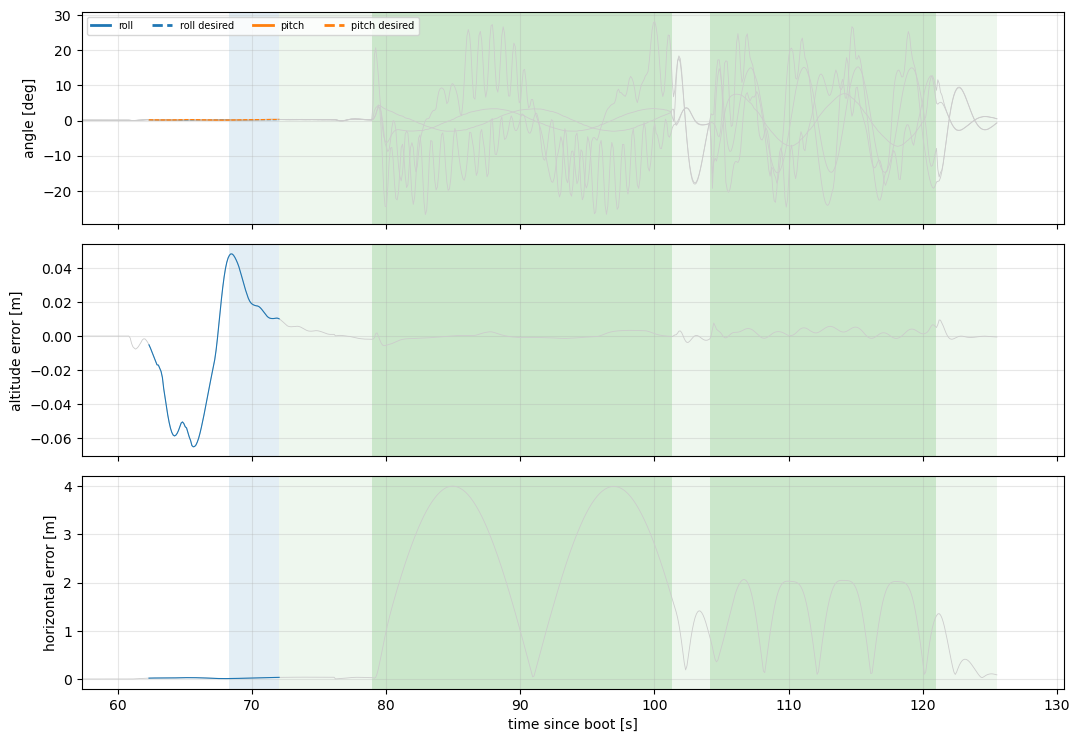

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
if has("ATT"):
    att = S["ATT"]
    plot_phase(axes[0], att["t"], att["Roll"], stock_flight, color="tab:blue", lw=0.8, label="roll")
    plot_phase(axes[0], att["t"], att["DesRoll"], stock_flight, color="tab:blue", ls="--", lw=0.8, label="roll desired")
    plot_phase(axes[0], att["t"], att["Pitch"], stock_flight, color="tab:orange", lw=0.8, label="pitch")
    plot_phase(axes[0], att["t"], att["DesPitch"], stock_flight, color="tab:orange", ls="--", lw=0.8,
               label="pitch desired")
    axes[0].set_ylabel("angle [deg]")
    legend(axes[0], fontsize=7, ncol=4)
    w = within(att["t"], stock_flight)
    error = np.hypot(att["DesRoll"] - att["Roll"], att["DesPitch"] - att["Pitch"])
    record("attitude_tracking", rms(error[w]) if w.any() else None)
if has("CTUN"):
    ctun = S["CTUN"]
    plot_phase(axes[1], ctun["t"], ctun["DAlt"] - ctun["Alt"], stock_flight, color="tab:blue", lw=0.8)
    axes[1].set_ylabel("altitude error [m]")
    w = within(ctun["t"], stock_flight)
    record("altitude_tracking", rms((ctun["DAlt"] - ctun["Alt"])[w]) if w.any() else None)
if has("PSCN", "PSCE"):
    pn, pe = S["PSCN"], S["PSCE"]
    error_e = np.interp(pn["t"], pe["t"], pe["TPE"] - pe["PE"])
    horizontal = np.hypot(pn["TPN"] - pn["PN"], error_e)
    plot_phase(axes[2], pn["t"], horizontal, stock_flight, color="tab:blue", lw=0.8)
    axes[2].set_ylabel("horizontal error [m]")
    w = within(pn["t"], stock_flight)
    record("stock_position_tracking", rms(horizontal[w]) if w.any() else None)
axes[2].set_xlabel("time since boot [s]")
for ax in axes:
    shade(ax)
    flight_xlim(ax)
fig.tight_layout()

## 3. Custom outer loop: trajectory tracking

Present only when the log has `INDB`. For each outer-active block, the notebook compares the DDS
flatness reference position (`RP*`) with the measured position (`P*`). The steady-tracking score drops
the first and last `EDGE_TRIM_S`, and those edges get their own transient metric. That keeps a harness
sequencing artifact (a reference that starts away from the vehicle, or stops abruptly) from hiding
whether the controller tracks well. It also keeps one from being mistaken for the other.

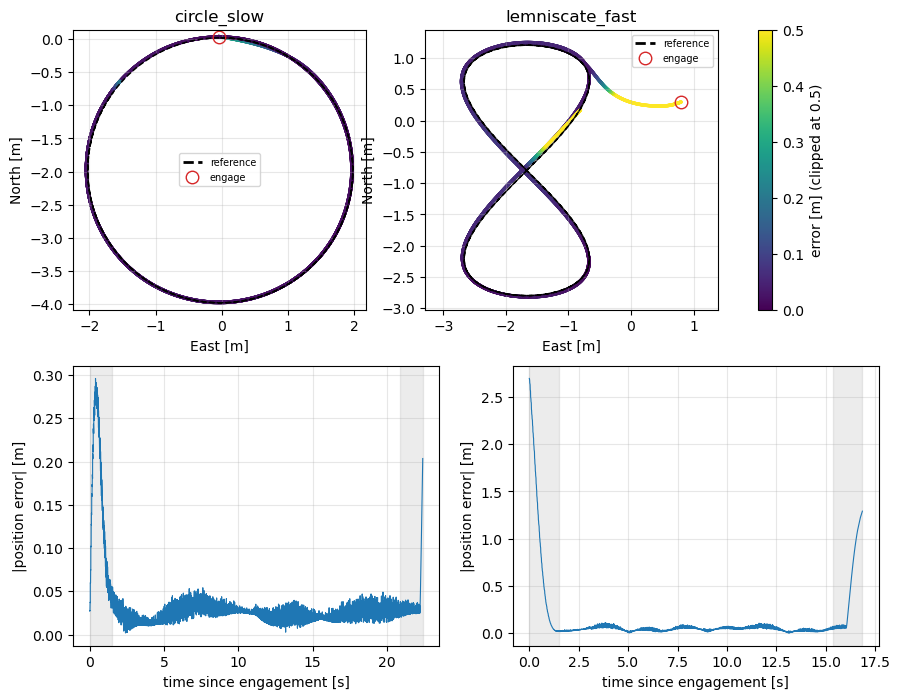

block               dur s     RMS  steady RMS  steady max  edge peak
circle_slow          22.4   0.052       0.026       0.055       0.30
lemniscate_fast      16.8   0.406       0.048       0.113       2.70
[  A] Custom outer loop: steady tracking RMS (worst block): 0.04814 m  (A≤0.1 B≤0.3 C≤0.75)  worst: lemniscate_fast
[  F] Custom outer loop: transient peak (worst block): 2.697 m  (A≤0.3 B≤1 C≤2.5)  worst: lemniscate_fast


In [9]:
block_stats = []
if outer_blocks:
    indb = S["INDB"]
    ref = np.column_stack([indb["RPx"], indb["RPy"], indb["RPz"]])
    meas = np.column_stack([indb["Px"], indb["Py"], indb["Pz"]])
    fig, axes = plt.subplots(2, len(outer_blocks), figsize=(5.2 * len(outer_blocks), 8), squeeze=False)
    for k, (a, b) in enumerate(outer_blocks):
        w = (indb["t"] >= a) & (indb["t"] <= b)
        t_rel = indb["t"][w] - a
        error = np.linalg.norm(ref[w] - meas[w], axis=1)
        steady = (t_rel > EDGE_TRIM_S) & (t_rel < t_rel[-1] - EDGE_TRIM_S)
        edges = ~steady
        block_stats.append({"name": block_names[k], "duration": b - a, "rms": rms(error),
                            "steady_rms": rms(error[steady]) if steady.any() else float("nan"),
                            "steady_max": error[steady].max() if steady.any() else float("nan"),
                            "edge_peak": error[edges].max()})
        top, bottom = axes[0, k], axes[1, k]
        top.plot(ref[w, 1], ref[w, 0], "k--", lw=1.1, label="reference")
        sc = top.scatter(meas[w, 1], meas[w, 0], c=error, s=2, cmap="viridis", vmin=0, vmax=0.5)
        top.plot(meas[w, 1][0], meas[w, 0][0], "o", mfc="none", mec="tab:red", ms=9, label="engage")
        top.set_aspect("equal", adjustable="datalim")
        top.set_xlabel("East [m]")
        top.set_ylabel("North [m]")
        top.set_title(block_names[k])
        legend(top, fontsize=7)
        bottom.plot(t_rel, error, lw=0.8)
        bottom.axvspan(0, EDGE_TRIM_S, color="gray", alpha=0.15)
        bottom.axvspan(t_rel[-1] - EDGE_TRIM_S, t_rel[-1], color="gray", alpha=0.15)
        bottom.set_xlabel("time since engagement [s]")
        bottom.set_ylabel("|position error| [m]")
    fig.colorbar(sc, ax=axes[0, :].tolist(), label="error [m] (clipped at 0.5)")
    plt.show()

    print(f"{'block':18s}{'dur s':>7s}{'RMS':>8s}{'steady RMS':>12s}{'steady max':>12s}{'edge peak':>11s}")
    for s in block_stats:
        print(f"{s['name']:18s}{s['duration']:7.1f}{s['rms']:8.3f}{s['steady_rms']:12.3f}"
              f"{s['steady_max']:12.3f}{s['edge_peak']:11.2f}")
    worst = max(block_stats, key=lambda s: s["steady_rms"])
    record("outer_tracking_steady", worst["steady_rms"], f"worst: {worst['name']}")
    worst = max(block_stats, key=lambda s: s["edge_peak"])
    record("outer_engagement_peak", worst["edge_peak"], f"worst: {worst['name']}")
else:
    print("no custom outer-loop blocks in this log")

## 4. Custom inner loop: INDI ω̇ inversion

INDI predicts the body angular acceleration its increment should produce (`INDI.P*`) and compares
it with the filtered measurement (`INDI.M*`). If the effectiveness model and actuator timing match
the plant, the two overlap and NRMSE is near 0. An attenuated or wrong-signed prediction gives
NRMSE ≈ 1 or more.

The lag scan shifts the measurement later by 0–120 ms. If NRMSE collapses at some lag, the mismatch
is mostly *phase* (unmodeled delay) rather than *gain*. Axes with excitation below
`MIN_EXCITATION_RAD_S2` are reported but not graded, because NRMSE on a quiet axis divides noise by
noise.

INDI log period 2.50 ms
window            axis    exc rms   NRMSE      R²  best lag  NRMSE@lag  graded
circle_slow       roll       2.70   1.043   -0.09      48 ms      0.255  yes
circle_slow       pitch      0.40   1.456   -1.12      40 ms      1.000  no
circle_slow       yaw        0.03   0.371    0.86      32 ms      0.228  no
lemniscate_fast   roll       4.70   1.019   -0.04      50 ms      0.193  yes
lemniscate_fast   pitch      3.08   1.133   -0.28      54 ms      0.265  yes
lemniscate_fast   yaw        0.72   0.771    0.41      44 ms      0.242  no


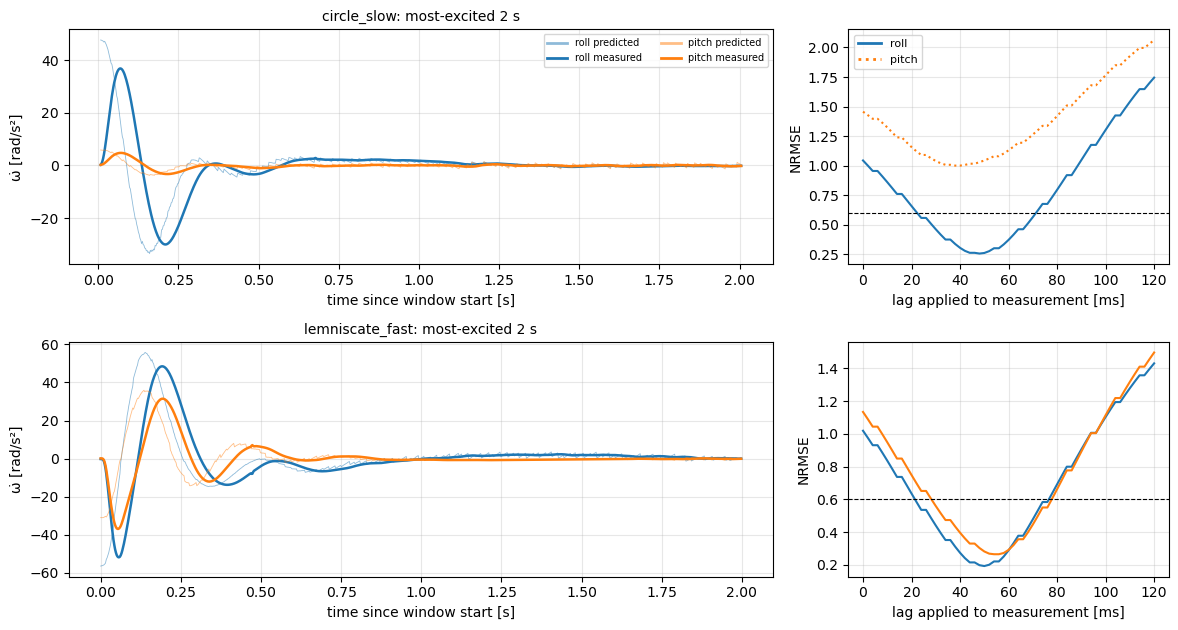

[  F] INDI: ω̇ inversion NRMSE (worst excited roll/pitch): 1.133   (A≤0.3 B≤0.45 C≤0.6)  worst: lemniscate_fast pitch
[  F] INDI: ω̇ prediction → measurement lag: 54 ms  (A≤10 B≤25 C≤50)
[  A] INDI: saturation fraction: 0 frac  (A≤0.001 B≤0.01 C≤0.02)


In [10]:
LAGS_MS = np.arange(0, 121, 2)


def nrmse(pred, meas):
    return rms(pred - meas) / rms(meas) if rms(meas) > 1e-9 else float("inf")


if has("INDI") and engaged:
    indi = S["INDI"]
    dt_indi = np.median(np.diff(indi["t"]))
    windows = list(zip(block_names, outer_blocks)) or [("engaged", iv) for iv in engaged]
    graded, lags = [], []
    fig, axes = plt.subplots(len(windows), 2, figsize=(12, 3.2 * len(windows)), squeeze=False,
                             gridspec_kw={"width_ratios": [2.2, 1]})
    print(f"INDI log period {dt_indi * 1e3:.2f} ms")
    print(f"{'window':18s}{'axis':6s}{'exc rms':>9s}{'NRMSE':>8s}{'R²':>8s}{'best lag':>10s}{'NRMSE@lag':>11s}  graded")
    for row, (name, (a, b)) in enumerate(windows):
        w = (indi["t"] >= a) & (indi["t"] <= b)
        t_w = indi["t"][w]
        # Show the 2 s excerpt with the most roll excitation.
        excitation = np.convolve(indi["Mx"][w] ** 2, np.ones(int(2 / dt_indi)), mode="valid")
        start = t_w[int(np.argmax(excitation))] if excitation.size else t_w[0]
        excerpt = (t_w >= start) & (t_w <= start + 2)
        for axis, label, color in [("x", "roll", "tab:blue"), ("y", "pitch", "tab:orange"), ("z", "yaw", "tab:gray")]:
            pred, meas = indi[f"P{axis}"][w], indi[f"M{axis}"][w]
            curve = [nrmse(pred[: len(pred) - int(round(l * 1e-3 / dt_indi))],
                           meas[int(round(l * 1e-3 / dt_indi)):]) for l in LAGS_MS]
            best = int(np.argmin(curve))
            excited = rms(meas) >= MIN_EXCITATION_RAD_S2
            grade_it = excited and axis in "xy"
            r2 = 1 - np.sum((meas - pred) ** 2) / max(np.sum((meas - meas.mean()) ** 2), 1e-12)
            print(f"{name:18s}{label:6s}{rms(meas):9.2f}{nrmse(pred, meas):8.3f}{r2:8.2f}"
                  f"{LAGS_MS[best]:8d} ms{curve[best]:11.3f}  {'yes' if grade_it else 'no'}")
            if grade_it:
                graded.append((nrmse(pred, meas), f"{name} {label}"))
                lags.append(LAGS_MS[best])
            if axis in "xy":
                axes[row, 0].plot(t_w[excerpt] - a, pred[excerpt], color=color, lw=0.6, alpha=0.5,
                                  label=f"{label} predicted")
                axes[row, 0].plot(t_w[excerpt] - a, meas[excerpt], color=color, lw=1.8,
                                  label=f"{label} measured")
                axes[row, 1].plot(LAGS_MS, curve, color=color, ls="-" if excited else ":", label=label)
        axes[row, 0].set_title(f"{name}: most-excited 2 s", fontsize=10)
        axes[row, 0].set_ylabel("ω̇ [rad/s²]")
        axes[row, 0].set_xlabel("time since window start [s]")
        axes[row, 1].axhline(THRESHOLDS["omega_nrmse"][0][2], color="k", ls="--", lw=0.8)
        axes[row, 1].set_ylabel("NRMSE")
        axes[row, 1].set_xlabel("lag applied to measurement [ms]")
    legend(axes[0, 0], fontsize=7, ncol=2)
    legend(axes[0, 1], fontsize=8)
    fig.tight_layout()
    plt.show()
    if graded:
        worst = max(graded)
        record("omega_nrmse", worst[0], f"worst: {worst[1]}")
        record("omega_lag", max(lags))
    else:
        record("omega_nrmse", None, "no axis excited enough")
        record("omega_lag", None)
    on = within(indi["t"], engaged)
    record("indi_saturation", indi["S"][on].mean())
else:
    print("no INDI log while engaged")

## 5. Actuators

Motor PWM (`RCOU`) for every flight. Measured rotor speed comes from `ESC` telemetry (the JSON
rotor-dynamics backend provides it), and the measured-RPM path's fallback flag comes from `INDC`. Large or
lasting differences between motors while holding point to trim, CG, or a mixer layout that
doesn't match the plant.

[  B] Motors: output at a limit: 0.00158 frac  (A≤0.001 B≤0.01 C≤0.05)  PWM range 1000-2000
[  A] Motors: hover output spread: 0.01622 % range  (A≤2 B≤5 C≤10)  means 1303, 1303, 1303, 1303
[  A] INDI: measured-RPM fallback fraction: 0 frac  (A≤0.01 B≤0.1 C≤0.5)


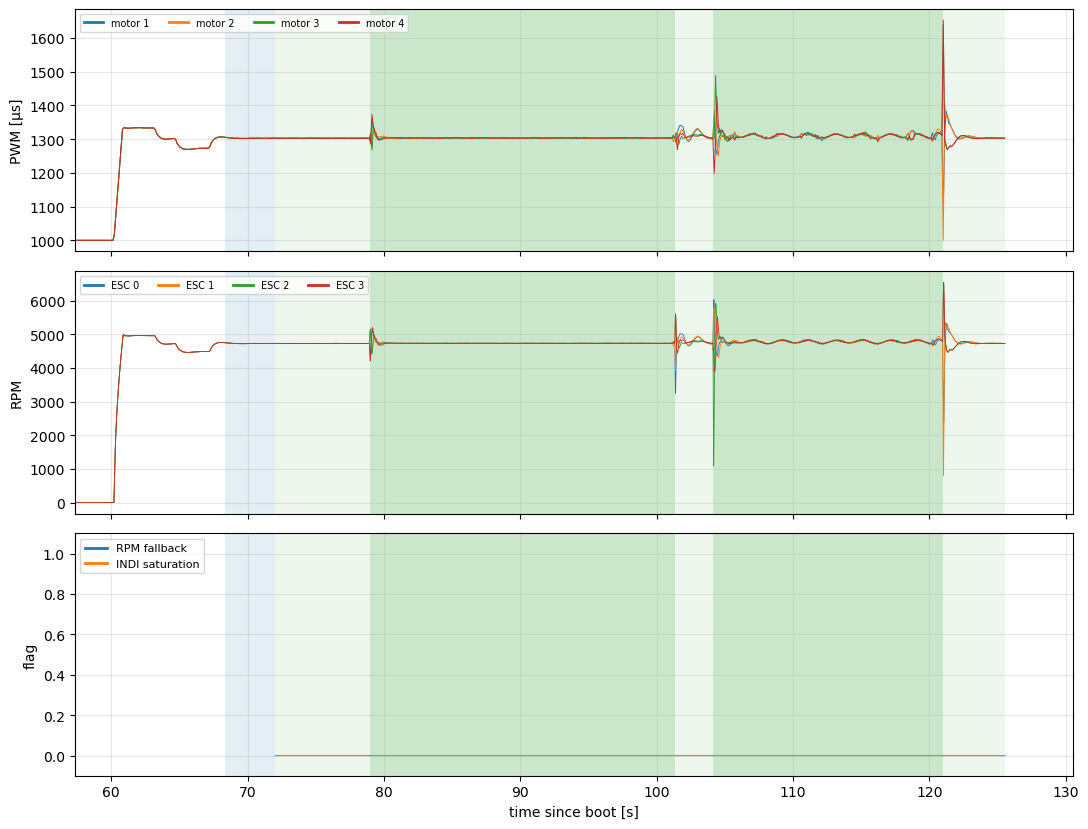

In [11]:
FRAME_MOTORS = {1: 4, 2: 6, 3: 8, 4: 8, 5: 6, 7: 3, 10: 1, 12: 12, 14: 10}
n_motors = FRAME_MOTORS.get(int(PARAMS.get("FRAME_CLASS", 1)), 4)
pwm_min = PARAMS.get("MOT_PWM_MIN", 0) or 1000
pwm_max = PARAMS.get("MOT_PWM_MAX", 0) or 2000
panels = 1 + has("ESC") + has("INDC")
fig, axes = plt.subplots(panels, 1, figsize=(11, 2.8 * panels), sharex=True, squeeze=False)
axes = axes[:, 0]
if has("RCOU"):
    rcou = S["RCOU"]
    pwm = np.column_stack([rcou[f"C{k + 1}"] for k in range(n_motors)])
    for k in range(n_motors):
        axes[0].plot(rcou["t"], pwm[:, k], lw=0.7, label=f"motor {k + 1}")
    axes[0].set_ylabel("PWM [µs]")
    legend(axes[0], fontsize=7, ncol=n_motors)
    margin = 0.02 * (pwm_max - pwm_min)
    air = within(rcou["t"], airborne)
    at_limit = ((pwm >= pwm_max - margin) | (pwm <= pwm_min + margin)).any(axis=1)
    record("motor_saturation", at_limit[air].mean() if air.any() else None,
           f"PWM range {pwm_min:g}-{pwm_max:g}")
    hold = within(rcou["t"], stock_hold)
    if hold.any():
        means = pwm[hold].mean(axis=0)
        record("motor_hover_spread", 100 * np.ptp(means) / (pwm_max - pwm_min),
               "means " + ", ".join(f"{m:.0f}" for m in means))
    else:
        record("motor_hover_spread", None, "no stock hold window")
row = 1
if has("ESC"):
    esc = S["ESC"]
    for k in sorted(set(esc["Instance"].astype(int))):
        w = esc["Instance"] == k
        axes[row].plot(esc["t"][w], esc["RPM"][w], lw=0.6, label=f"ESC {k}")
    axes[row].set_ylabel("RPM")
    legend(axes[row], fontsize=7, ncol=n_motors)
    row += 1
if has("INDC"):
    indc = S["INDC"]
    axes[row].plot(indc["t"], indc["FB"], lw=0.8, label="RPM fallback")
    if has("INDI"):
        axes[row].plot(S["INDI"]["t"], S["INDI"]["S"], lw=0.8, label="INDI saturation")
    axes[row].set_ylim(-0.1, 1.1)
    axes[row].set_ylabel("flag")
    legend(axes[row], fontsize=8)
    on = within(indc["t"], engaged)
    record("rpm_fallback", indc["FB"][on].mean() if on.any() else None)
axes[-1].set_xlabel("time since boot [s]")
for ax in axes:
    shade(ax)
    flight_xlim(ax)
fig.tight_layout()

## 6. Estimator and vibration

EKF3 innovation test ratios (`XKF4`, core 0) show whether the estimate the controllers rely on stays
consistent with its sensors. `VIBE` is the standard IMU vibration metric. Both usually look clean in
SITL, and a bad value here means the controller scores above aren't trustworthy.

[  A] Estimator: peak innovation test ratio: 0.04   (A≤0.3 B≤0.5 C≤1)
[  A] Vibration: peak VIBE level: 0.295 m/s²  (A≤15 B≤30 C≤60)


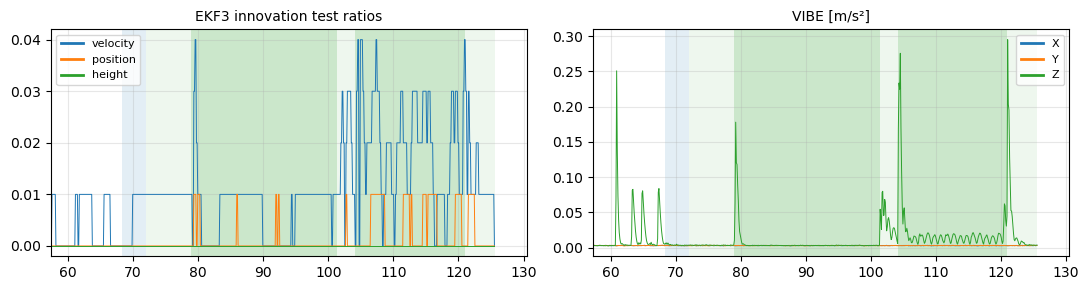

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), squeeze=False)
axes = axes[0]
if has("XKF4"):
    x4 = S["XKF4"]
    for field, label in [("SV", "velocity"), ("SP", "position"), ("SH", "height")]:
        axes[0].plot(x4["t"], x4[field], lw=0.7, label=label)
    axes[0].set_title("EKF3 innovation test ratios", fontsize=10)
    legend(axes[0], fontsize=8)
    air = within(x4["t"], airborne)
    record("ekf_test_ratio", max(x4[f][air].max() for f in ("SV", "SP", "SH")) if air.any() else None)
if has("VIBE"):
    vibe = S["VIBE"]
    for axis in "XYZ":
        axes[1].plot(vibe["t"], vibe[f"Vibe{axis}"], lw=0.7, label=axis)
    axes[1].set_title("VIBE [m/s²]", fontsize=10)
    legend(axes[1], fontsize=8)
    air = within(vibe["t"], airborne)
    record("vibration", max(vibe[f"Vibe{a}"][air].max() for a in "XYZ") if air.any() else None)
for ax in axes:
    shade(ax)
    flight_xlim(ax)
fig.tight_layout()

## 7. Flight in 3D (mesh-plotter)

The whole airborne span, downsampled to at most `MAX_ANIMATION_FRAMES` frames. Position comes from
EKF core 0 (`XKF1`). Attitude comes from simulator truth (`SIM`) when available, otherwise from the
attitude estimate (`ATT`). The custom outer-loop reference path is drawn dashed, and the flown path is
drawn gray. Frames are converted from NED/FRD to z-up NWU/FLU. Set `ANIMATE = False` to skip.

In [13]:
from geometry import SO3, SE3
from mesh_plotter.meshes import Line, MeshBase, Axes3DMesh
from mesh_plotter.animator_3d import Animator3D

NED_TO_NWU = np.diag([1.0, -1.0, -1.0])


def quad_mesh(arm, motors=4):
    # Arms in FLU; X layout for quads. Front arms red, the rest black, blue stick = thrust axis.
    offset = 45.0 if motors == 4 and PARAMS.get("FRAME_TYPE", 1) != 0 else 0.0
    lines = []
    for k in range(motors):
        angle = np.deg2rad(offset + 360.0 * k / motors)
        color = "red" if np.cos(angle) > 0.1 else "black"
        lines.append(Line([np.zeros(3), arm * np.array([np.cos(angle), np.sin(angle), 0.0])], color=color))
    lines.append(Line([np.zeros(3), np.array([0.0, 0.0, 0.8 * arm])], color="blue"))
    return MeshBase(lines=lines)


def rotation_from_quaternion(w, x, y, z):
    n = np.sqrt(w * w + x * x + y * y + z * z)
    w, x, y, z = w / n, x / n, y / n, z / n
    return np.array([
        [1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
        [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
        [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)],
    ])


def rotation_from_euler_deg(roll, pitch, yaw):
    r, p, y = np.radians([roll, pitch, yaw])
    Rz = np.array([[np.cos(y), -np.sin(y), 0], [np.sin(y), np.cos(y), 0], [0, 0, 1]])
    Ry = np.array([[np.cos(p), 0, np.sin(p)], [0, 1, 0], [-np.sin(p), 0, np.cos(p)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(r), -np.sin(r)], [0, np.sin(r), np.cos(r)]])
    return Rz @ Ry @ Rx


if ANIMATE and airborne and has("XKF1") and (has("SIM") or has("ATT")):
    a, b = airborne[0][0], airborne[-1][1]
    x1 = S["XKF1"]
    t_frames = np.linspace(a, b, min(MAX_ANIMATION_FRAMES, int((b - a) / 0.1)))
    position = np.column_stack([np.interp(t_frames, x1["t"], x1[f]) for f in ("PN", "PE", "PD")])
    if has("SIM"):
        sim = S["SIM"]
        nearest = np.clip(np.searchsorted(sim["t"], t_frames), 0, len(sim["t"]) - 1)
        rotations = [rotation_from_quaternion(*(sim[q][i] for q in ("Q1", "Q2", "Q3", "Q4"))) for i in nearest]
    else:
        att = S["ATT"]
        nearest = np.clip(np.searchsorted(att["t"], t_frames), 0, len(att["t"]) - 1)
        rotations = [rotation_from_euler_deg(att["Roll"][i], att["Pitch"][i], att["Yaw"][i]) for i in nearest]
    origin = position[0] * np.array([1, 1, 0])
    position_nwu = (position - origin) @ NED_TO_NWU
    poses = [SE3.fromVecAndQuat(p, SO3.fromR(NED_TO_NWU @ R @ NED_TO_NWU))
             for p, R in zip(position_nwu, rotations)]
    times = list(t_frames - a)

    low, high = position_nwu.min(axis=0), position_nwu.max(axis=0)
    half = max(np.max(high[:2] - low[:2]) / 2 + 1.0, 2.0)
    centre = (low + high) / 2
    arm = 0.08 * half
    identity = SE3.identity()
    style = {"figure.dpi": 72, "figure.figsize": (6.5, 5.0), "animation.frame_format": "jpeg"}
    plt.rcParams["animation.embed_limit"] = 40.0
    with plt.rc_context(style):
        animator = Animator3D(xlim=(centre[0] - half, centre[0] + half), ylim=(centre[1] - half, centre[1] + half),
                              zlim=(0.0, max(high[2] + 1.0, 2.0)))
    flown = MeshBase(lines=[Line([np.array(p) for p in position_nwu], color="gray", spec="-")])
    animator.addMeshSequence(flown, [identity, identity], [times[0], times[-1]])
    if outer_blocks:
        indb = S["INDB"]
        for (b0, b1) in outer_blocks:
            w = (indb["t"] >= b0) & (indb["t"] <= b1)
            ref = np.column_stack([indb["RPx"][w], indb["RPy"][w], indb["RPz"][w]])[::20]
            ref_nwu = (ref - origin) @ NED_TO_NWU
            path = MeshBase(lines=[Line([np.array(p) for p in ref_nwu], color="tab:green", spec="--")])
            animator.addMeshSequence(path, [identity, identity], [times[0], times[-1]])
    animator.addMeshSequence(quad_mesh(arm, n_motors), poses, times)
    animator.ax.view_init(elev=30, azim=-60)
    animation = animator.animate(dt=times[1] - times[0], notebook_mode=True)
    plt.close(animator.fig)
    with plt.rc_context(style):
        display(HTML(animation.to_jshtml()))
else:
    print("animation skipped")

## Scorecard

**Overall grade.** If any gating metric is an F, the flight is **FAIL**. Otherwise the letter comes
from the mean grade points of all graded metrics (A = 4, B = 3, C = 2, F = 0; ≥ 3.5 → A, ≥ 2.5 → B,
≥ 1.5 → C).

In [14]:
def overall_grade(scores):
    graded = {k: v for k, v in scores.items() if v["grade"] != "n/a"}
    if not graded:
        return "n/a", float("nan"), []
    failures = [k for k, v in graded.items() if v["grade"] == "F" and THRESHOLDS[k][2]]
    points = np.mean([GRADE_POINTS[v["grade"]] for v in graded.values()])
    if failures:
        return "FAIL", points, failures
    return ("A" if points >= 3.5 else "B" if points >= 2.5 else "C" if points >= 1.5 else "F"), points, []


grade, points, failures = overall_grade(SCORES)
rows = []
for key, (bounds, unit, gating, label, why) in THRESHOLDS.items():
    s = SCORES.get(key, {"value": float("nan"), "grade": "n/a", "detail": "not in this log"})
    value = "—" if not np.isfinite(s["value"]) else f"{s['value']:.4g}"
    rows.append(
        f"<tr><td style='background:{GRADE_COLORS[s['grade']]};color:white;text-align:center;font-weight:bold'>"
        f"{s['grade']}</td><td><b>{label}</b><br><small>{why}</small></td>"
        f"<td style='text-align:right'>{value} {unit}</td>"
        f"<td style='white-space:nowrap'>A≤{bounds[0]:g}<br>B≤{bounds[1]:g}<br>C≤{bounds[2]:g}</td>"
        f"<td>{'gating' if gating else 'diagnostic'}</td><td><small>{s['detail']}</small></td></tr>")
banner_color = GRADE_COLORS.get(grade, GRADE_COLORS["F"] if grade == "FAIL" else "#9e9e9e")
banner = (f"<div style='font-size:1.4em;padding:8px;background:{banner_color};color:white'>"
          f"Overall: <b>{grade}</b> &nbsp; ({points:.2f} grade points over "
          f"{sum(s['grade'] != 'n/a' for s in SCORES.values())} graded metrics)"
          f"{' — failed: ' + ', '.join(THRESHOLDS[k][3] for k in failures) if failures else ''}</div>"
          f"<div><small>{log_path}</small></div>")
display(HTML(banner + "<table><tr><th>grade</th><th>metric</th><th>value</th><th>bounds</th><th>role</th>"
             "<th>detail</th></tr>" + "".join(rows) + "</table>"))

grade,metric,value,bounds,role,detail
A,"Stock hold: peak roll/pitch ratePeak |(p, q)| from the IMU while the stock controller holds position (custom controller off, target speed ≈ 0). A healthy hold is nearly motionless. C = the harness's 1 rad/s handover gate. A limit cycle (for example a mixer that doesn't match the plant) fails here first.",0.005373 rad/s,A≤0.1B≤0.3C≤1,gating,over 3.7 s of stock hold
A,Stock hold: rate buzzRMS of the high-passed roll/pitch gyro (0.5 s moving average removed) during stock hold. Measures oscillation that the low-rate attitude log hides.,0.06579 deg/s,A≤0.5B≤2C≤5,gating,
C,"Custom controller: rate buzzThe same high-pass gyro RMS while the custom controller is engaged. Maneuvering adds some legitimate content, so the bounds are looser. An inner-loop limit cycle drives this sharply up.",11.89 deg/s,A≤3B≤8C≤15,gating,over 53.5 s engaged
A,Stock: attitude tracking RMSRMS of ATT desired − actual roll/pitch while the stock controller flies (custom controller off). ATT is logged at about 10 Hz.,0.01212 deg,A≤0.5B≤1.5C≤4,diagnostic,
A,Stock: altitude tracking RMSRMS of CTUN desired − actual altitude while the stock controller flies.,0.0377 m,A≤0.1B≤0.3C≤0.75,diagnostic,
A,Stock: horizontal position tracking RMSRMS horizontal distance between the stock position-controller target and the estimate (PSCN/PSCE) while the stock controller flies.,0.023 m,A≤0.1B≤0.3C≤1,diagnostic,
A,"Custom outer loop: steady tracking RMS (worst block)Per engaged outer-loop block (INDB.FB = 0), RMS of |reference − measured position| excluding the first and last EDGE_TRIM_S. Worst block shown.",0.04814 m,A≤0.1B≤0.3C≤0.75,gating,worst: lemniscate_fast
F,"Custom outer loop: transient peak (worst block)Largest position error in the first/last EDGE_TRIM_S of any block. Usually reflects how the harness sequences references (origin latch, abrupt stop) rather than the controller.",2.697 m,A≤0.3B≤1C≤2.5,diagnostic,worst: lemniscate_fast
F,"INDI: ω̇ inversion NRMSE (worst excited roll/pitch)RMS(predicted − measured ω̇) / RMS(measured ω̇) on roll/pitch, only on axes excited above MIN_EXCITATION_RAD_S2. Measures whether the effectiveness model inverts the plant. C = the frozen 0.6 harness gate.",1.133,A≤0.3B≤0.45C≤0.6,gating,worst: lemniscate_fast pitch
F,INDI: ω̇ prediction → measurement lagTime shift of the measurement that minimizes NRMSE (worst excited axis). A large lag means the prediction leads the plant: unmodeled actuator or filter delay.,54 ms,A≤10B≤25C≤50,diagnostic,
